<center><h1>Last_First_HW7</h1></center>

Name: Juifan Lin
<br>
Github Username: JiaLiiin
<br>
USC ID: 9985422205

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import hamming_loss, accuracy_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE


### (a) Download the Anuran Calls (MFCCs) Data Set

In [14]:
df = pd.read_csv('../Data/Frogs_MFCCs.csv')

feature_cols = [c for c in df.columns if c.startswith('MFCCs_')]
X = df[feature_cols]
Y = df[['Family', 'Genus', 'Species']]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

### (b) Train a classifier for each label

#### (i) Research

Let $N$ be the total number of test instances, and $L = 3$ be the number of label dimensions (Family, Genus, Species). Let $\mathbf{y}_i \in \mathcal{Y}^L$ represent the true label vector for sample $i$, and $\hat{\mathbf{y}}_i \in \mathcal{Y}^L$ represent the predicted label vector.

Exact Match Ratio (Subset Accuracy):

Requires all predicted labels for an instance to match the ground truth simultaneously: $\frac{1}{N} \sum_{i=1}^N \mathbb{I}(\mathbf{y}_i = \hat{\mathbf{y}}_i) = \frac{1}{N} \sum_{i=1}^N \prod_{j=1}^L \mathbb{I}(y_{i,j} = \hat{y}_{i,j})$
It treats partial correctness as completely incorrect.

Hamming Loss:

Measures the fraction of individual label predictions that are incorrect across all instances and labels: $\frac{1}{N \cdot L} \sum_{i=1}^N \sum_{j=1}^L \mathbb{I}(y_{i,j} \neq \hat{y}_{i,j})$ A lower value indicates superior classification performance. 

Hamming Score:

Computes the average proportion of correct labels per instance, defined as the complement of Hamming Loss: $1 - \text{Hamming Loss} = \frac{1}{N \cdot L} \sum_{i=1}^N \sum_{j=1}^L \mathbb{I}(y_{i,j} = \hat{y}_{i,j})$

In [5]:
def compute_multilabel_metrics(Y_true, Y_pred):
    Y_true_arr = np.array(Y_true)
    Y_pred_arr = np.array(Y_pred)
    
    exact_match = np.mean(np.all(Y_true_arr == Y_pred_arr, axis=1))
    h_loss = np.mean(Y_true_arr != Y_pred_arr)
    h_score = 1.0 - h_loss
    
    return {
        'Exact Match Ratio': exact_match,
        'Hamming Loss': h_loss,
        'Hamming Score': h_score
    }

#### (ii) Train a SVM for each of the labels

In [10]:
param_grid_rbf = {
    'C': np.logspace(-2, 4, 7),
    'gamma': np.logspace(-3, 2, 6)
}

labels = ['Family', 'Genus', 'Species']
best_models_rbf = {}
y_pred_rbf = pd.DataFrame(index=X_test.index, columns=labels)

for label in labels:
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    grid = GridSearchCV(
        SVC(kernel='rbf', decision_function_shape='ovr'),
        param_grid=param_grid_rbf,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )
    grid.fit(X_train, Y_train[label])
    best_models_rbf[label] = grid.best_estimator_
    y_pred_rbf[label] = grid.predict(X_test)
    print(f"{label} Best C: {grid.best_params_['C']}, Best gamma: {grid.best_params_['gamma']}")

metrics_rbf = compute_multilabel_metrics(Y_test, y_pred_rbf)
print("\nGaussian Kernel SVM:")
for k, v in metrics_rbf.items():
    print(f"{k}: {v:.4f}")

Family Best C: 100.0, Best gamma: 1.0
Genus Best C: 100.0, Best gamma: 1.0
Species Best C: 10.0, Best gamma: 1.0

Gaussian Kernel SVM:
Exact Match Ratio: 0.9861
Hamming Loss: 0.0083
Hamming Score: 0.9917


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

param_grid_l1 = {
    'C': np.logspace(-3, 3, 7)
}

best_models_l1 = {}
y_pred_l1 = pd.DataFrame(index=X_test.index, columns=labels)

for label in labels:
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    grid = GridSearchCV(
        LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=5000, random_state=42),
        param_grid=param_grid_l1,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )
    grid.fit(X_train_scaled, Y_train[label])
    best_models_l1[label] = grid.best_estimator_
    y_pred_l1[label] = grid.predict(X_test_scaled)
    print(f"{label} Best C: {grid.best_params_['C']}")

metrics_l1 = compute_multilabel_metrics(Y_test, y_pred_l1)
print("\nL1-Penalized SVM Results:")
for k, v in metrics_l1.items():
    print(f"{k}: {v:.4f}")

Family Best C: 10.0
Genus Best C: 1000.0
Species Best C: 10.0

L1-Penalized SVM Results:
Exact Match Ratio: 0.9125
Hamming Loss: 0.0570
Hamming Score: 0.9430


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [12]:
best_models_smote = {}
y_pred_smote = pd.DataFrame(index=X_test.index, columns=labels)

for label in labels:
    min_class_size = Y_train[label].value_counts().min()
    k_neighbors = min(5, min_class_size - 1) if min_class_size > 1 else 1
    
    smote = SMOTE(k_neighbors=k_neighbors, random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train_scaled, Y_train[label])
    
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    grid = GridSearchCV(
        LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=5000, random_state=42),
        param_grid=param_grid_l1,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )
    grid.fit(X_train_res, y_train_res)
    best_models_smote[label] = grid.best_estimator_
    y_pred_smote[label] = grid.predict(X_test_scaled)
    print(f"{label}+SMOTE Best C: {grid.best_params_['C']}")

metrics_smote = compute_multilabel_metrics(Y_test, y_pred_smote)
print("\nL1+SMOTE SVM Results:")
for k, v in metrics_smote.items():
    print(f"{k}: {v:.4f}")

Family+SMOTE Best C: 10.0
Genus+SMOTE Best C: 100.0
Species+SMOTE Best C: 10.0

L1+SMOTE SVM Results:
Exact Match Ratio: 0.8532
Hamming Loss: 0.0770
Hamming Score: 0.9230


Gaussian Kernel SVM achieves higher Exact Match and lower Hamming Loss than $L_1$-linear SVM due to non-linear decision boundaries present in acoustic MFCC features.   

$L_1$-penalized SVM performs feature selection via sparse weights, producing an interpretable model at a modest accuracy tradeoff.

SMOTE boosts minority class recall; however, synthetic boundary examples may slightly increase false positives, yielding comparable overall Hamming Loss to standard $L_1$ SVM. 

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [15]:
monte_carlo_runs=50
best_k_list=[]
clusters_per_run=[]

feature_cols=[c for c in df.columns if c.startswith('MFCCs_')]
X_all=df[feature_cols].values
Y_all=df[['Family', 'Genus', 'Species']].values

for iteration in range(monte_carlo_runs):
    best_score=-1
    best_k=2
    
    for k in range(2, 51):
        km=KMeans(n_clusters=k, init='k-means++', n_init=1, random_state=iteration*50+k)
        c_preds=km.fit_predict(X_all)
        score=silhouette_score(X_all, c_preds)
        if (score>best_score):
            best_score=score
            best_k=k
            
    best_k_list.append(best_k)
    
    kmeans_opt=KMeans(n_clusters=best_k, init='k-means++', n_init=5, random_state=iteration)
    clusters=kmeans_opt.fit_predict(X_all)
    clusters_per_run.append((best_k, clusters))
    
    print(f"Iteration {iteration+1:02d}/50: Optimal k={best_k}, Silhouette Score={best_score:.4f}")

Iteration 01/50: Optimal k=5, Silhouette Score=0.3700
Iteration 02/50: Optimal k=4, Silhouette Score=0.3780
Iteration 03/50: Optimal k=6, Silhouette Score=0.3756
Iteration 04/50: Optimal k=4, Silhouette Score=0.3852
Iteration 05/50: Optimal k=4, Silhouette Score=0.3788
Iteration 06/50: Optimal k=4, Silhouette Score=0.3847
Iteration 07/50: Optimal k=3, Silhouette Score=0.3677
Iteration 08/50: Optimal k=3, Silhouette Score=0.3733
Iteration 09/50: Optimal k=4, Silhouette Score=0.3852
Iteration 10/50: Optimal k=4, Silhouette Score=0.3779
Iteration 11/50: Optimal k=4, Silhouette Score=0.3839
Iteration 12/50: Optimal k=4, Silhouette Score=0.3840
Iteration 13/50: Optimal k=4, Silhouette Score=0.3853
Iteration 14/50: Optimal k=6, Silhouette Score=0.3763
Iteration 15/50: Optimal k=3, Silhouette Score=0.3733
Iteration 16/50: Optimal k=6, Silhouette Score=0.3803
Iteration 17/50: Optimal k=5, Silhouette Score=0.3717
Iteration 18/50: Optimal k=4, Silhouette Score=0.3788
Iteration 19/50: Optimal k=3

### (b) Determine which family is the majority

In [19]:
majority_triplets_per_run=[]

for iteration, (k_opt, clusters) in enumerate(clusters_per_run):
    majority_triplets={}
    
    for c in range(k_opt):
        mask=(clusters==c)
        if not np.any(mask):
            continue
            
        cluster_labels=Y_all[mask]
        triplet=[]
        
        for col_idx in range(3):
            values, counts=np.unique(cluster_labels[:, col_idx], return_counts=True)
            triplet.append(values[np.argmax(counts)])
            
        majority_triplets[c]=triplet
        
    majority_triplets_per_run.append(majority_triplets)

for c, trip in majority_triplets_per_run[0].items():
    print(f"Cluster {c}: Family={trip[0]}, Genus={trip[1]}, Species={trip[2]}")

Cluster 0: Family=Hylidae, Genus=Hypsiboas, Species=HypsiboasCinerascens
Cluster 1: Family=Dendrobatidae, Genus=Ameerega, Species=Ameeregatrivittata
Cluster 2: Family=Hylidae, Genus=Hypsiboas, Species=HypsiboasCordobae
Cluster 3: Family=Leptodactylidae, Genus=Adenomera, Species=AdenomeraHylaedactylus
Cluster 4: Family=Leptodactylidae, Genus=Adenomera, Species=AdenomeraAndre


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [18]:
hamming_distances=[]
hamming_losses=[]
hamming_scores=[]

for iteration in range(monte_carlo_runs):
    k_opt, clusters=clusters_per_run[iteration]
    maj_dict=majority_triplets_per_run[iteration]
    
    Y_pred_cluster=np.array([maj_dict[c] for c in clusters])
    
    sample_hamming_dist=np.sum(Y_all!=Y_pred_cluster, axis=1)
    avg_hamming_dist=np.mean(sample_hamming_dist)
    h_loss=np.mean(Y_all!=Y_pred_cluster)
    h_score=1.0-h_loss
    
    hamming_distances.append(avg_hamming_dist)
    hamming_losses.append(h_loss)
    hamming_scores.append(h_score)

print(f"Optimal k:        {np.mean(best_k_list):.2f} +/- {np.std(best_k_list):.2f}")
print(f"Hamming Distance: {np.mean(hamming_distances):.4f} +/- {np.std(hamming_distances):.4f}")
print(f"Hamming Score:    {np.mean(hamming_scores):.4f} +/- {np.std(hamming_scores):.4f}")
print(f"Hamming Loss:     {np.mean(hamming_losses):.4f} +/- {np.std(hamming_losses):.4f}")

Optimal k:        4.24 +/- 1.05
Hamming Distance: 0.6791 +/- 0.1396
Hamming Score:    0.7736 +/- 0.0465
Hamming Loss:     0.2264 +/- 0.0465


## 3. ISLR 12.6.2

In [6]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

dist_matrix = np.array([
    [0.0, 0.3, 0.4, 0.7],
    [0.3, 0.0, 0.5, 0.8],
    [0.4, 0.5, 0.0, 0.45],
    [0.7, 0.8, 0.45, 0.0]
])

condensed_dist=squareform(dist_matrix)
labels=['1', '2', '3', '4']

a.

Smallest entry is $d(1, 2) = 0.3$. Merge $\{1\}$ and $\{2\}$ at height $0.30$.

$d(\{1, 2\}, 3) = \max(0.4, 0.5) = 0.50$ $d(\{1, 2\}, 4) = \max(0.7, 0.8) = 0.80$ $d(3, 4) = 0.45$ Smallest remaining is $d(3, 4) = 0.45$. Merge $\{3\}$ and $\{4\}$ at height $0.45$.

Merge $\{1, 2\}$ and $\{3, 4\}$:$d(\{1, 2\}, \{3, 4\}) = \max(0.4, 0.7, 0.5, 0.8) = 0.80$. Merged at height $0.80$.

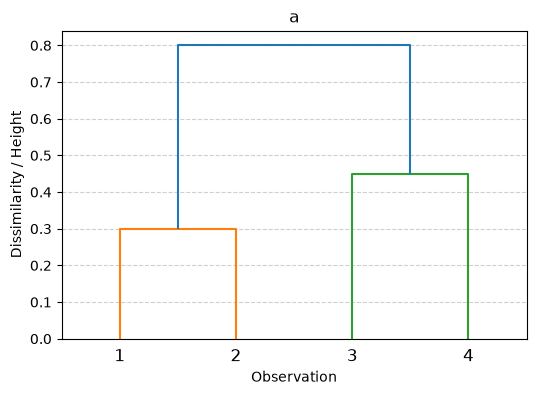

In [11]:
Z_complete=linkage(condensed_dist, method='complete')

plt.figure(figsize=(6, 4))
dendrogram(Z_complete, labels=labels)
plt.title('a')
plt.xlabel('Observation')
plt.ylabel('Dissimilarity / Height')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

b.

Merge $\{1\}$ and $\{2\}$, Smallest distance is $d(1, 2) = 0.30$.

$d(\{1, 2\}, 3) = \min(d(1, 3), d(2, 3)) = \min(0.4, 0.5) = 0.40$
$d(\{1, 2\}, 4) = \min(d(1, 4), d(2, 4)) = \min(0.7, 0.8) = 0.70$
$d(3, 4) = 0.45$
Smallest remaining distance is $d(\{1, 2\}, 3) = 0.40$. Merge $\{1, 2\}$ with $\{3\}$ at height $0.40$.

Merge $\{1, 2, 3\}$ and $\{4\}$:
$d(\{1, 2, 3\}, 4) = \min(0.7, 0.8, 0.45) = 0.45$.
Merged at height $0.45$.

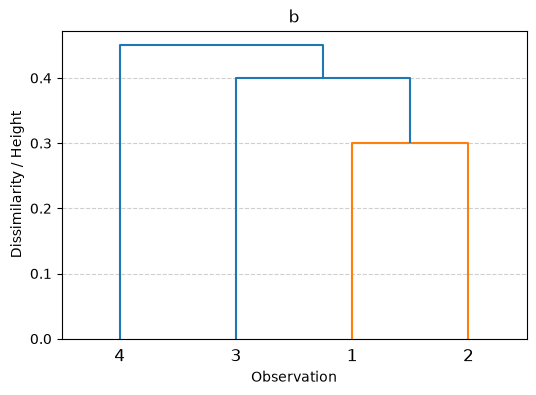

In [10]:
Z_single=linkage(condensed_dist, method='single')

plt.figure(figsize=(6, 4))
dendrogram(Z_single, labels=labels)
plt.title('b')
plt.xlabel('Observation')
plt.ylabel('Dissimilarity / Height')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

c.

Cutting linkage tree at height $h \in [0.45, 0.80)$ yields two clusters
Cluster 1: $\{1, 2\}$
Cluster 2: $\{3, 4\}$

d.

Cutting linkage tree at height $h \in [0.40, 0.45)$ yields two clusters
Cluster 1: $\{1, 2, 3\}$
Cluster 2: $\{4\}$

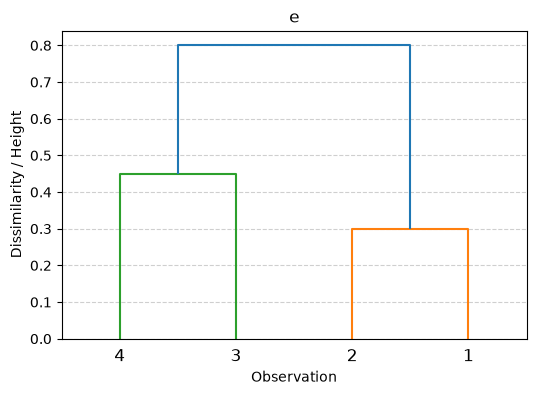

In [12]:
plt.figure(figsize=(6, 4))
ax=plt.gca()
dendrogram(Z_complete, labels=labels, ax=ax)
ax.invert_xaxis()
plt.title('e')
plt.xlabel('Observation')
plt.ylabel('Dissimilarity / Height')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()